# PLFS Labour-Market Intelligence

## Purpose
Use official PLFS data to derive labour-market indicators and context
for the Skill & Outcome Intelligence Engine.

## Data Sources
- cperv12025.csv — person-level PLFS data
- chhv12025.csv — household-level PLFS data
- MPER_Q2_Q4_2025.csv — quarterly PLFS data
- 2_Data_LayoutPLFS_Q2025.xlsx — PLFS data layout/reference

## Planned Use
- Employment and labour-market analysis
- Occupation and industry intelligence
- Earnings analysis
- District/state labour-market context
- Support for skill-demand and career intelligence

## 1. Load the PLFS Person-Level Dataset

Load cperv12025.csv and verify its size and basic structure.

In [1]:
import pandas as pd

plfs_person = pd.read_csv(
    "../data/cperv12025.csv",
    low_memory=False
)

print("Shape:", plfs_person.shape)
print("\nColumns:")
print(plfs_person.columns.tolist())

Shape: (1148634, 153)

Columns:
['file_id', 'sch', 'qtr', 'month', 'visit', 'sec', 'st', 'dc', 'nss_reg', 'bstrm', 'strm', 'grp', 'sstrm', 'sro', 'mfsu', 'sss', 'ssu', 'srl', 'rel', 'sex', 'age', 'marst', 'gedu_lvl', 'tedu_lvl', 'grade', 'yrsbef1', 'yrsaft', 'iflastyr', 'mnths', 'curr_att', 'secondary', 'voc', 'trg', 'trg_com', 'voc_compl', 'voc_fld', 'voc_dur', 'voc_typ', 'voc_fund', 'voc_cert', 'pas', 'ind_pas', 'ocu_pas', 'has_sas', 'loc_pas', 'etyp_pas', 'wrkr_pas', 'job_pas', 'leave_pas', 'ssec_pas', 'ecoprd_pas', 'sas', 'ind_sas', 'ocu_sas', 'loc_sas', 'etyp_sas', 'wrkr_sas', 'job_sas', 'leave_sas', 'ssec_sas', 'ecoprd_sas', 'wrk_365', 'dur_pas', 'dur_sas', 'eff_pas', 'dur_unp', 'evr_wrk', 'rea_nw', 'rea', 'das17', 'ind17', 'hr17', 'ern17', 'das27', 'ind27', 'hr27', 'ern27', 'hr7', 'ahr7', 'das16', 'ind16', 'hr16', 'ern16', 'das26', 'ind26', 'hr26', 'ern26', 'hr6', 'ahr6', 'das15', 'ind15', 'hr15', 'ern15', 'das25', 'ind25', 'hr25', 'ern25', 'hr5', 'ahr5', 'das14', 'ind14', 'hr14

- Interpretation: The new PLFS person-level dataset contains 1,148,634 records and 153 variables, giving us much richer individual-level employment, education, vocational-training, occupation, industry, earnings, and work-history information.

- Conclusion: This is a much stronger foundation for our labour/employment intelligence than the earlier 7,000-row synthetic dataset.

## 2. Audit PLFS Data Quality

Check missing values, duplicates, and data types in the 1.15M-record PLFS person dataset before selecting variables.

In [2]:
print("Duplicate rows:", plfs_person.duplicated().sum())

print("\nMissing values — top 20:")
print(
    plfs_person.isna()
    .sum()
    .sort_values(ascending=False)
    .head(20)
)

print("\nData types:")
print(plfs_person.dtypes.value_counts())

print("\nSample:")
display(plfs_person.head())

Duplicate rows: 0

Missing values — top 20:
das21        1135234
ind21        1135234
ind22        1134933
das22        1134933
ind23        1134837
das23        1134837
das24        1134348
ind24        1134348
das25        1133713
ind25        1133713
das27        1133479
ind27        1133479
das26        1133019
ind26        1133019
voc_compl    1131861
mnths        1131819
dur_unp      1128414
eff_pas      1126687
job_sas      1115434
ssec_sas     1115434
dtype: int64

Data types:
int64      83
float64    66
str         4
Name: count, dtype: int64

Sample:


,file_id,sch,qtr,month,visit,sec,st,dc,nss_reg,bstrm,...,ocu_cws,ern_reg,ern_self,nsc,mult,totalsd,zst,caph,smallh,panel
0,CFVP5,104,Q1,1,V1,1,19,17,193,D017,...,611.0,0,7500,12,119669,1,1401,41,4,5
1,CFVP5,104,Q1,1,V1,1,19,17,193,D017,...,235.0,0,1500,12,119669,1,1401,41,4,5
2,CFVP5,104,Q1,1,V1,1,19,17,193,D017,...,NaN,0,0,12,119669,1,1401,41,4,5
3,CFVP5,104,Q1,1,V1,1,19,17,193,D017,...,NaN,0,0,12,119669,1,1401,41,4,5
4,CFVP5,104,Q1,1,V1,1,19,17,193,D017,...,611.0,0,4500,12,119669,1,1401,41,4,5


- Interpretation: The PLFS data has 0 duplicate rows. The high missingness is mainly in variables that apply only to specific employment/training situations, so it is not automatically a data-quality problem.

- Conclusion: The dataset is usable; next we’ll identify the specific variables relevant to employment, skills, occupation, industry, and earnings before preprocessing.

## 3. Inspect Relevant PLFS Variables
Identify the actual PLFS fields available for education, vocational training, employment, occupation, industry, and earnings.

In [3]:
relevant_columns = [
    "age",
    "sex",
    "gedu_lvl",
    "tedu_lvl",
    "voc",
    "trg",
    "voc_fld",
    "voc_dur",
    "voc_typ",
    "voc_fund",
    "voc_cert",
    "evr_wrk",
    "rea_nw",
    "rea",
    "acws",
    "aind_cws",
    "ocu_cws",
    "ern_reg",
    "ern_self",
    "tothrs_wrk",
    "mult",
]

print("Relevant PLFS columns:\n")

for column in relevant_columns:
    print(f"{column}: {plfs_person[column].dtype}")

print("\nSample values:")
display(plfs_person[relevant_columns].head())

Relevant PLFS columns:

age: int64
sex: int64
gedu_lvl: int64
tedu_lvl: int64
voc: float64
trg: float64
voc_fld: float64
voc_dur: float64
voc_typ: float64
voc_fund: float64
voc_cert: float64
evr_wrk: float64
rea_nw: float64
rea: float64
acws: int64
aind_cws: float64
ocu_cws: float64
ern_reg: int64
ern_self: int64
tothrs_wrk: int64
mult: int64

Sample values:


,age,sex,gedu_lvl,tedu_lvl,voc,trg,voc_fld,voc_dur,voc_typ,voc_fund,...,evr_wrk,rea_nw,rea,acws,aind_cws,ocu_cws,ern_reg,ern_self,tothrs_wrk,mult
0,52,1,8,1,2.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,11,1.0,611.0,0,7500,33,119669
1,44,2,8,1,6.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,11,85.0,235.0,0,1500,29,119669
2,23,2,12,1,6.0,NaN,NaN,NaN,NaN,NaN,...,2.0,NaN,7.0,93,NaN,NaN,0,0,0,119669
3,14,2,7,1,6.0,NaN,NaN,NaN,NaN,NaN,...,2.0,NaN,4.0,91,NaN,NaN,0,0,0,119669
4,49,1,10,1,2.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,11,1.0,611.0,0,4500,37,119669


- Interpretation: The PLFS dataset contains useful fields for education, vocational training, employment status, occupation, industry, earnings, and work hours, with many conditional fields.

- Conclusion: Next we'll identify the exact employment/training codes and their official meanings before creating any ML features.

## 5. Create a PLFS Employment Indicator
Create a basic current-employment flag from the official PLFS CWS status field, using the PLFS code definitions rather than guessing. The official metadata identifies acws as Current Weekly Status.

### 5.1. Inspect the CWS code labels
Before creating the flag, let's see whether the downloaded data contains value labels.

In [4]:
print(plfs_person["acws"].value_counts().sort_index())

acws
11    171184
12     15914
21     67351
31    120744
41       524
42      1678
51     69873
61       629
62      4845
71       416
72      2757
81     25744
82      4011
91    287522
92    176650
93     49211
94     38696
95     13794
97     15348
98      1089
99     80654
Name: count, dtype: int64


- Interpretation: The PLFS dataset contains all major CWS status codes, with 11, 91, and 92 among the most frequent.

- Conclusion: We still need the official code-value mapping before creating an employment flag; we should not guess the meanings.

## Create Official Employment Flag
Convert PLFS acws into an employment indicator using the official PLFS status definitions. Codes 11–72 represent work/activity statuses, while 81/82 are seeking/available for work.

In [5]:
# Official PLFS CWS employment classification

work_codes = [11, 12, 21, 31, 41, 42, 51, 61, 62, 71, 72]

plfs_person["employed_cws"] = (
    plfs_person["acws"].isin(work_codes).astype(int)
)

print("CWS Employment Distribution:")
print(plfs_person["employed_cws"].value_counts())

print("\nEmployment Rate:")
print(
    round(plfs_person["employed_cws"].mean() * 100, 2),
    "%"
)

CWS Employment Distribution:
employed_cws
0    692719
1    455915
Name: count, dtype: int64

Employment Rate:
39.69 %


C:\Users\HP\AppData\Local\Temp\ipykernel_25804\1270067820.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  plfs_person["employed_cws"] = (


- Interpretation: The PLFS sample gives 39.69% currently employed (CWS). The warning is only a pandas performance warning; the calculation completed correctly.

- Conclusion: We now have a usable employment indicator; next we'll analyze employment by education, vocational training, occupation, and industry.

## Employment by Education & Training
Measure how current employment varies across education and vocational-training categories in the real PLFS data.

Algorithm: Group-wise employment-rate analysis.

In [6]:
analysis_columns = [
    "gedu_lvl",
    "tedu_lvl",
    "voc",
    "trg"
]

for column in analysis_columns:
    print("\n" + "=" * 60)
    print(column)

    result = (
        plfs_person
        .groupby(column)["employed_cws"]
        .agg(["count", "mean"])
        .rename(columns={"mean": "employment_rate"})
    )

    result["employment_rate"] = (
        result["employment_rate"] * 100
    ).round(2)

    display(result.sort_values("employment_rate", ascending=False).head(20))


gedu_lvl


,count,employment_rate
gedu_lvl,,
11,12847,67.87
13,34256,59.85
3,25,56.00
12,112264,54.06
2,1404,48.65
7,176589,47.91
8,152779,45.07
10,135843,43.27
6,143315,37.22



tedu_lvl


,count,employment_rate
tedu_lvl,,
14,1007,72.99
8,6472,72.70
4,1893,70.47
13,1805,69.03
3,7786,68.85
11,6062,65.84
7,137,65.69
16,3781,63.98
6,8141,63.03



voc


,count,employment_rate
voc,,
4.0,92066,94.88
3.0,70015,83.54
2.0,84559,83.53
5.0,28243,76.52
1.0,35422,63.23
6.0,514054,29.94



trg


,count,employment_rate
trg,,
2.0,244123,28.89
1.0,3801,24.34


- Interpretation: Vocational-training category voc shows a large employment-rate difference, while education levels also vary substantially.

- Conclusion: PLFS vocational training and education variables are promising features for employment intelligence; next we should map the codes to their official meanings before using them.

## Map PLFS Codes to Meanings
Verify the official meanings of gedu_lvl, tedu_lvl, voc, and trg before using them as ML features.

In [7]:
# Inspect the distinct codes present in the relevant PLFS fields

code_columns = [
    "gedu_lvl",
    "tedu_lvl",
    "voc",
    "trg"
]

for column in code_columns:
    print(f"\n{column}")
    print(sorted(plfs_person[column].dropna().unique()))


gedu_lvl
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(10), np.int64(11), np.int64(12), np.int64(13)]

tedu_lvl
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16)]

voc
[np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0)]

trg
[np.float64(1.0), np.float64(2.0)]


gedu_lvl → General education level<br>
tedu_lvl → Technical education level<br>
voc → Vocational training<br>
trg → Training-related indicator/status

- Interpretation: All four PLFS fields contain multiple coded categories, but the output gives only the numeric codes, not their official labels.

- Conclusion: We should not assign meanings to these codes ourselves; next we'll use the PLFS layout/codebook to map them correctly.

## Prepare Official PLFS Feature Mapping

Create a clean feature reference using the verified PLFS variable meanings before modelling. The official catalogue confirms gedu_lvl, tedu_lvl, voc, trg, acws, occupation, industry and earnings fields in cperv12025.

In [8]:
plfs_feature_map = {
    "age": "Age",
    "sex": "Gender",
    "gedu_lvl": "General education level",
    "tedu_lvl": "Technical education level",
    "voc": "Whether received vocational/technical training",
    "trg": "Whether received training/course for higher education or employment exams",
    "voc_fld": "Field of vocational training",
    "voc_dur": "Duration of vocational training",
    "voc_typ": "Type of vocational training",
    "voc_fund": "Source of funding for training",
    "voc_cert": "Nature of certifying body",
    "evr_wrk": "Whether ever worked",
    "acws": "Current weekly status",
    "aind_cws": "Industry under CWS",
    "ocu_cws": "Occupation under CWS",
    "ern_reg": "Earnings from regular salaried/wage activity",
    "ern_self": "Earnings from self-employment",
    "tothrs_wrk": "Total hours worked during the week",
    "mult": "Survey multiplier"
}

for field, meaning in plfs_feature_map.items():
    print(f"{field:15} -> {meaning}")

age             -> Age
sex             -> Gender
gedu_lvl        -> General education level
tedu_lvl        -> Technical education level
voc             -> Whether received vocational/technical training
trg             -> Whether received training/course for higher education or employment exams
voc_fld         -> Field of vocational training
voc_dur         -> Duration of vocational training
voc_typ         -> Type of vocational training
voc_fund        -> Source of funding for training
voc_cert        -> Nature of certifying body
evr_wrk         -> Whether ever worked
acws            -> Current weekly status
aind_cws        -> Industry under CWS
ocu_cws         -> Occupation under CWS
ern_reg         -> Earnings from regular salaried/wage activity
ern_self        -> Earnings from self-employment
tothrs_wrk      -> Total hours worked during the week
mult            -> Survey multiplier


- Interpretation: We now have a defined feature map for the key PLFS variables we plan to use.

- Conclusion: Next we can create a clean PLFS analysis dataset using only relevant fields and preserve the survey weight (mult).

## Create Clean PLFS Analysis Dataset
Keep only the PLFS fields relevant to employment, education, vocational training, occupation, industry, earnings, and survey weighting.

In [9]:
plfs_features = [
    "st",
    "dc",
    "age",
    "sex",
    "gedu_lvl",
    "tedu_lvl",
    "voc",
    "trg",
    "voc_fld",
    "voc_dur",
    "voc_typ",
    "voc_fund",
    "voc_cert",
    "evr_wrk",
    "acws",
    "aind_cws",
    "ocu_cws",
    "ern_reg",
    "ern_self",
    "tothrs_wrk",
    "mult"
]

plfs_clean = plfs_person[plfs_features].copy()

print("Clean PLFS shape:", plfs_clean.shape)
print("\nColumns retained:", len(plfs_clean.columns))
print(plfs_clean.head())

Clean PLFS shape: (1148634, 21)

Columns retained: 21
   st  dc  age  sex  gedu_lvl  tedu_lvl  voc  trg  voc_fld  voc_dur  ...  \
0  19  17   52    1         8         1  2.0  NaN      NaN      NaN  ...   
1  19  17   44    2         8         1  6.0  NaN      NaN      NaN  ...   
2  19  17   23    2        12         1  6.0  NaN      NaN      NaN  ...   
3  19  17   14    2         7         1  6.0  NaN      NaN      NaN  ...   
4  19  17   49    1        10         1  2.0  NaN      NaN      NaN  ...   

   voc_fund  voc_cert  evr_wrk  acws  aind_cws  ocu_cws  ern_reg  ern_self  \
0       NaN       NaN      NaN    11       1.0    611.0        0      7500   
1       NaN       NaN      NaN    11      85.0    235.0        0      1500   
2       NaN       NaN      2.0    93       NaN      NaN        0         0   
3       NaN       NaN      2.0    91       NaN      NaN        0         0   
4       NaN       NaN      NaN    11       1.0    611.0        0      4500   

   tothrs_wrk    mul

- Interpretation: We reduced the 153-column PLFS dataset to 21 relevant fields while retaining the survey weight mult.

- Conclusion: The clean PLFS dataset is ready for the next analysis step.

## Isolate Maharashtra PLFS Data
Confirm how many PLFS records belong to Maharashtra so our analysis matches the Maharashtra-focused project.

In [10]:
print("State distribution:")
print(plfs_clean["st"].value_counts().sort_index())

print("\nMaharashtra records:")
print((plfs_clean["st"] == 28).sum())

State distribution:
st
1      21886
2      10363
3      30517
4       2153
5      11819
6      30304
7      13132
8      80791
9     176060
10     85505
11      2744
12      6527
13      4712
14      8958
15      6691
16      6080
17      7156
18     42465
19     50371
20     36747
21     41271
22     37804
23     90965
24     58728
25      2185
27     77494
28     38751
29     51156
30      2106
31      1176
32     24986
33     49410
34      1936
35      2071
36     31003
37      2611
Name: count, dtype: int64

Maharashtra records:
38751


- Interpretation: The dataset contains 38,751 Maharashtra records (st=28) out of the full PLFS dataset.

- Conclusion: We can now filter Maharashtra records and continue with district-level labour-market analysis.

## Filter Maharashtra Records
Create the Maharashtra-only PLFS dataset for our project analysis.

In [11]:
maharashtra_plfs = plfs_clean[
    plfs_clean["st"] == 28
].copy()

print("Maharashtra PLFS shape:", maharashtra_plfs.shape)
print("\nDistrict codes:")
print(
    maharashtra_plfs["dc"]
    .value_counts()
    .sort_index()
)

Maharashtra PLFS shape: (38751, 21)

District codes:
dc
1     2038
2     1519
3     1995
4     1482
5     1521
6     1441
7     1384
8     2156
9     2075
10    2116
11    1700
12    2376
13    1593
14    1543
15     947
16    1925
17    1645
18    1626
19    2222
20     166
21      83
22     322
23    1493
24    1539
25     409
26    1435
Name: count, dtype: int64


- Interpretation: Maharashtra has 38,751 records across 26 district codes.

- Conclusion: The Maharashtra subset is ready for district-level labour-market analysis.

<h2>District Sample Quality Check</h2>
Check whether every Maharashtra district has enough PLFS observations for reliable district-level analysis.

In [12]:
district_counts = (
    maharashtra_plfs["dc"]
    .value_counts()
    .sort_index()
)

print("District sample size:")
print(district_counts)

print("\nDistricts with fewer than 500 records:")
print(
    district_counts[district_counts < 500]
)

District sample size:
dc
1     2038
2     1519
3     1995
4     1482
5     1521
6     1441
7     1384
8     2156
9     2075
10    2116
11    1700
12    2376
13    1593
14    1543
15     947
16    1925
17    1645
18    1626
19    2222
20     166
21      83
22     322
23    1493
24    1539
25     409
26    1435
Name: count, dtype: int64

Districts with fewer than 500 records:
dc
20    166
21     83
22    322
25    409
Name: count, dtype: int64


- Interpretation: Most districts have 900+ records, but 4 districts have fewer than 500, so their estimates may be less stable.

- Conclusion: For district-level modelling/visualization, we should keep all districts but flag the low-sample districts rather than discard them.

<h2>District Employment Rate</h2>

- Calculate the weighted current employment rate for each Maharashtra district using PLFS survey weights.
- Algorithm: Weighted aggregation.

In [13]:
# PLFS CWS codes representing work/activity
work_codes = [11, 12, 21, 31, 41, 42, 51, 61, 62, 71, 72]

maharashtra_plfs["employed_cws"] = (
    maharashtra_plfs["acws"].isin(work_codes).astype(int)
)

district_employment = (
    maharashtra_plfs
    .groupby("dc")
    .apply(
        lambda g: pd.Series({
            "sample_size": len(g),
            "weighted_population": g["mult"].sum(),
            "employment_rate_pct": (
                (g["employed_cws"] * g["mult"]).sum()
                / g["mult"].sum()
                * 100
            )
        }),
        include_groups=False
    )
    .reset_index()
)

display(
    district_employment
    .sort_values("employment_rate_pct", ascending=False)
)

,dc,sample_size,weighted_population,employment_rate_pct
18,19,2222.0,232116699.0,48.441611
17,18,1626.0,175067111.0,47.287714
19,20,166.0,61356312.0,46.470890
12,13,1593.0,138304182.0,46.403365
10,11,1700.0,166114919.0,46.077202
8,9,2075.0,199188396.0,45.178820
7,8,2156.0,240969678.0,45.151210
11,12,2376.0,202361495.0,44.464340
14,15,947.0,132924016.0,43.633190
13,14,1543.0,209766097.0,43.477064


- Interpretation: Maharashtra district employment rates vary substantially, from about 36.87% to 48.44% in this weighted sample.

- Conclusion: This is useful for the district employment comparison and Maharashtra map/dashboard; next we'll map district codes to actual district names.

<h2>Get Official District Names</h2>

Map PLFS district codes to actual Maharashtra district names using the official PLFS district-code reference.

The official PLFS catalogue provides an Indian Districts Code-Name file for the 2025 data.

In [14]:
district_codes = pd.DataFrame({
    "dc": sorted(maharashtra_plfs["dc"].unique())
})

print(district_codes)

    dc
0    1
1    2
2    3
3    4
4    5
5    6
6    7
7    8
8    9
9   10
10  11
11  12
12  13
13  14
14  15
15  16
16  17
17  18
18  19
19  20
20  21
21  22
22  23
23  24
24  25
25  26


<h2>Employment vs Vocational Training</h2>

- Check whether PLFS vocational-training categories are associated with different employment rates.

- Algorithm: Weighted group-wise employment-rate analysis.

In [16]:
voc_employment = (
    maharashtra_plfs
    .groupby("voc")
    .apply(
        lambda g: pd.Series({
            "sample_size": len(g),
            "weighted_employment_rate_pct": (
                (g["employed_cws"] * g["mult"]).sum()
                / g["mult"].sum()
                * 100
            )
        }),
        include_groups=False
    )
    .reset_index()
)

voc_employment["weighted_employment_rate_pct"] = (
    voc_employment["weighted_employment_rate_pct"]
    .round(2)
)

display(
    voc_employment.sort_values(
        "weighted_employment_rate_pct",
        ascending=False
    )
)

,voc,sample_size,weighted_employment_rate_pct
1,2.0,959.0,93.78
3,4.0,2998.0,92.06
2,3.0,967.0,85.13
4,5.0,1413.0,81.10
0,1.0,732.0,64.55
5,6.0,21639.0,43.81


- Interpretation: Vocational-training groups show large differences in weighted employment rates, ranging from 43.81% to 93.78%.

- Conclusion: Vocational training is a strong candidate for our employment and skill-intelligence analysis, but we must map the codes to their official labels before presenting these results.

<h2>Employment by Age Group</h2>

- Analyze how employment varies by age in Maharashtra using PLFS weighted data.
- Algorithm: Weighted aggregation.

In [17]:
maharashtra_plfs["age_group"] = pd.cut(
    maharashtra_plfs["age"],
    bins=[0, 18, 25, 35, 45, 60, 100],
    labels=[
        "Below 18",
        "18-25",
        "26-35",
        "36-45",
        "46-60",
        "60+"
    ],
    right=True
)

age_employment = (
    maharashtra_plfs
    .groupby("age_group", observed=False)
    .apply(
        lambda g: pd.Series({
            "sample_size": len(g),
            "weighted_employment_rate_pct": (
                (g["employed_cws"] * g["mult"]).sum()
                / g["mult"].sum()
                * 100
            )
        }),
        include_groups=False
    )
    .reset_index()
)

age_employment["weighted_employment_rate_pct"] = (
    age_employment["weighted_employment_rate_pct"].round(2)
)

display(age_employment)

,age_group,sample_size,weighted_employment_rate_pct
0,Below 18,9743.0,2.57
1,18-25,4702.0,35.43
2,26-35,6345.0,67.27
3,36-45,6517.0,74.46
4,46-60,7281.0,64.28
5,60+,3795.0,27.55


- Interpretation: Employment is highest for ages 36–45 (74.46%) and lowest for below 18 (2.57%) and 60+ (27.55%).

- Conclusion: Age is useful for labour-market segmentation and employment analysis, but not necessarily as a direct causal factor.

<h2>Employment by Education</h2>

- Analyze how weighted employment rates vary across general education levels in Maharashtra.
- Algorithm: Weighted aggregation.

In [18]:
education_employment = (
    maharashtra_plfs
    .groupby("gedu_lvl")
    .apply(
        lambda g: pd.Series({
            "sample_size": len(g),
            "weighted_employment_rate_pct": (
                (g["employed_cws"] * g["mult"]).sum()
                / g["mult"].sum()
                * 100
            )
        }),
        include_groups=False
    )
    .reset_index()
)

education_employment["weighted_employment_rate_pct"] = (
    education_employment["weighted_employment_rate_pct"]
    .round(2)
)

display(
    education_employment.sort_values(
        "weighted_employment_rate_pct",
        ascending=False
    )
)

,gedu_lvl,sample_size,weighted_employment_rate_pct
9,11,686.0,68.83
11,13,1239.0,66.05
10,12,4254.0,52.66
7,8,6166.0,46.94
0,1,10671.0,41.67
6,7,3365.0,41.61
5,6,4908.0,41.51
1,2,13.0,40.20
8,10,4130.0,37.61
4,5,3222.0,28.54


- Interpretation: Employment rates vary across education levels, with some higher education groups showing higher employment, though very small groups have unstable estimates.

- Conclusion: Education can support employment and career analysis; next we'll examine technical/vocational education and employment.

<h2>Employment by Technical Education</h2>

- Analyze how technical-education levels relate to weighted employment rates in Maharashtra.
- Algorithm: Weighted aggregation.

In [19]:
technical_employment = (
    maharashtra_plfs
    .groupby("tedu_lvl")
    .apply(
        lambda g: pd.Series({
            "sample_size": len(g),
            "weighted_employment_rate_pct": (
                (g["employed_cws"] * g["mult"]).sum()
                / g["mult"].sum()
                * 100
            )
        }),
        include_groups=False
    )
    .reset_index()
)

technical_employment["weighted_employment_rate_pct"] = (
    technical_employment["weighted_employment_rate_pct"]
    .round(2)
)

display(
    technical_employment.sort_values(
        "weighted_employment_rate_pct",
        ascending=False
    )
)

,tedu_lvl,sample_size,weighted_employment_rate_pct
4,5,1.0,100.00
14,15,1.0,100.00
7,8,274.0,72.41
10,11,313.0,67.71
8,9,57.0,65.54
12,13,65.0,65.51
15,16,170.0,63.14
5,6,401.0,61.97
2,3,831.0,55.31
3,4,87.0,54.95


- Interpretation: Technical-education groups show different employment rates, but several categories have very small samples, making their percentages unreliable.

- Conclusion: Technical education is useful as an employment feature, but we should account for sample size when using it.

<h2>Employment by Vocational Training Field</h2>

- Check which vocational-training fields are associated with higher employment rates in Maharashtra.
- Algorithm: Weighted aggregation.

In [ ]:
voc_field_employment = (
    maharashtra_plfs
    .dropna(subset=["voc_fld"])
    .groupby("voc_fld")
    .apply(
        lambda g: pd.Series({
            "sample_size": len(g),
            "weighted_employment_rate_pct": (
                (g["employed_cws"] * g["mult"]).sum()
                / g["mult"].sum()
                * 100
            )
        }),
        include_groups=False
    )
    .reset_index()
)

voc_field_employment["weighted_employment_rate_pct"] = (
    voc_field_employment["weighted_employment_rate_pct"]
    .round(2)
)Shape: (1148634, 153)

Columns:
['file_id', 'sch', 'qtr', 'month', 'visit', 'sec', 'st', 'dc', 'nss_reg', 'bstrm', 'strm', 'grp', 'sstrm', 'sro', 'mfsu', 'sss', 'ssu', 'srl', 'rel', 'sex', 'age', 'marst', 'gedu_lvl', 'tedu_lvl', 'grade', 'yrsbef1', 'yrsaft', 'iflastyr', 'mnths', 'curr_att', 'secondary', 'voc', 'trg', 'trg_com', 'voc_compl', 'voc_fld', 'voc_dur', 'voc_typ', 'voc_fund', 'voc_cert', 'pas', 'ind_pas', 'ocu_pas', 'has_sas', 'loc_pas', 'etyp_pas', 'wrkr_pas', 'job_pas', 'leave_pas', 'ssec_pas', 'ecoprd_pas', 'sas', 'ind_sas', 'ocu_sas', 'loc_sas', 'etyp_sas', 'wrkr_sas', 'job_sas', 'leave_sas', 'ssec_sas', 'ecoprd_sas', 'wrk_365', 'dur_pas', 'dur_sas', 'eff_pas', 'dur_unp', 'evr_wrk', 'rea_nw', 'rea', 'das17', 'ind17', 'hr17', 'ern17', 'das27', 'ind27', 'hr27', 'ern27', 'hr7', 'ahr7', 'das16', 'ind16', 'hr16', 'ern16', 'das26', 'ind26', 'hr26', 'ern26', 'hr6', 'ahr6', 'das15', 'ind15', 'hr15', 'ern15', 'das25', 'ind25', 'hr25', 'ern25', 'hr5', 'ahr5', 'das14', 'ind14', 'hr14', 'ern14', 'das24', 'ind24', 'hr24', 'ern24', 'hr4', 'ahr4', 'das13', 'ind13', 'hr13', 'ern13', 'das23', 'ind23', 'hr23', 'ern23', 'hr3', 'ahr3', 'das12', 'ind12', 'hr12', 'ern12', 'das22', 'ind22', 'hr22', 'ern22', 'hr2', 'ahr2', 'das11', 'ind11', 'hr11', 'ern11', 'das21', 'ind21', 'hr21', 'ern21', 'hr1', 'ahr1', 'tothrs_wrk', 'totadl_wrk', 'acws', 'aind_cws', 'ocu_cws', 'ern_reg', 'ern_self', 'nsc', 'mult', 'totalsd', 'zst', 'caph', 'smallh', 'panel']



Duplicate rows: 0

Missing values — top 20:
das21        1135234
ind21        1135234
ind22        1134933
das22        1134933
ind23        1134837
das23        1134837
das24        1134348
ind24        1134348
das25        1133713
ind25        1133713
das27        1133479
ind27        1133479
das26        1133019
ind26        1133019
voc_compl    1131861
mnths        1131819
dur_unp      1128414
eff_pas      1126687
job_sas      1115434
ssec_sas     1115434
dtype: int64
...
str         4
Name: count, dtype: int64

Sample:
Output is truncated. View as a scrollable element or open in a text editor. Adjust cell output settings...
file_id	sch	qtr	month	visit	sec	st	dc	nss_reg	bstrm	...	ocu_cws	ern_reg	ern_self	nsc	mult	totalsd	zst	caph	smallh	panel
0	CFVP5	104	Q1	1	V1	1	19	17	193	D017	...	611.0	0	7500	12	119669	1	1401	41	4	5
1	CFVP5	104	Q1	1	V1	1	19	17	193	D017	...	235.0	0	1500	12	119669	1	1401	41	4	5
2	CFVP5	104	Q1	1	V1	1	19	17	193	D017	...	NaN	0	0	12	119669	1	1401	41	4	5
3	CFVP5	104	Q1	1	V1	1	19	17	193	D017	...	NaN	0	0	12	119669	1	1401	41	4	5
4	CFVP5	104	Q1	1	V1	1	19	17	193	D017	...	611.0	0	4500	12	119669	1	1401	41	4	5
5 rows × 153 columns




Relevant PLFS columns:

age: int64
sex: int64
gedu_lvl: int64
tedu_lvl: int64
voc: float64
trg: float64
voc_fld: float64
voc_dur: float64
voc_typ: float64
voc_fund: float64
voc_cert: float64
evr_wrk: float64
rea_nw: float64
rea: float64
acws: int64
aind_cws: float64
ocu_cws: float64
ern_reg: int64
ern_self: int64
tothrs_wrk: int64
mult: int64

Sample values:
age	sex	gedu_lvl	tedu_lvl	voc	trg	voc_fld	voc_dur	voc_typ	voc_fund	...	evr_wrk	rea_nw	rea	acws	aind_cws	ocu_cws	ern_reg	ern_self	tothrs_wrk	mult
0	52	1	8	1	2.0	NaN	NaN	NaN	NaN	NaN	...	NaN	NaN	NaN	11	1.0	611.0	0	7500	33	119669
1	44	2	8	1	6.0	NaN	NaN	NaN	NaN	NaN	...	NaN	NaN	NaN	11	85.0	235.0	0	1500	29	119669
2	23	2	12	1	6.0	NaN	NaN	NaN	NaN	NaN	...	2.0	NaN	7.0	93	NaN	NaN	0	0	0	119669
3	14	2	7	1	6.0	NaN	NaN	NaN	NaN	NaN	...	2.0	NaN	4.0	91	NaN	NaN	0	0	0	119669
4	49	1	10	1	2.0	NaN	NaN	NaN	NaN	NaN	...	NaN	NaN	NaN	11	1.0	611.0	0	4500	37	119669
5 rows × 21 columns





acws
11    171184
12     15914
21     67351
31    120744
41       524
42      1678
51     69873
61       629
62      4845
71       416
72      2757
81     25744
82      4011
91    287522
92    176650
93     49211
94     38696
95     13794
97     15348
98      1089
99     80654
Name: count, dtype: int64



CWS Employment Distribution:
employed_cws
0    692719
1    455915
Name: count, dtype: int64

Employment Rate:
39.69 %
C:\Users\HP\AppData\Local\Temp\ipykernel_25804\1270067820.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  plfs_person["employed_cws"] = (





============================================================
gedu_lvl
count	employment_rate
gedu_lvl		
11	12847	67.87
13	34256	59.85
3	25	56.00
12	112264	54.06
2	1404	48.65
7	176589	47.91
8	152779	45.07
10	135843	43.27
6	143315	37.22
1	254706	30.70
5	114455	18.68
4	10151	1.49

============================================================
tedu_lvl
count	employment_rate
tedu_lvl		
14	1007	72.99
8	6472	72.70
4	1893	70.47
13	1805	69.03
3	7786	68.85
11	6062	65.84
7	137	65.69
16	3781	63.98
6	8141	63.03
9	1883	62.77
15	51	62.75
2	272	61.76
5	77	61.04
12	80	60.00
10	257	58.37
1	1108930	38.71

============================================================
voc
count	employment_rate
voc		
4.0	92066	94.88
3.0	70015	83.54
2.0	84559	83.53
5.0	28243	76.52
1.0	35422	63.23
6.0	514054	29.94

============================================================
trg
count	employment_rate
trg		
2.0	244123	28.89
1.0	3801	24.34




gedu_lvl
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(10), np.int64(11), np.int64(12), np.int64(13)]

tedu_lvl
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16)]

voc
[np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0)]

trg
[np.float64(1.0), np.float64(2.0)]




age             -> Age
sex             -> Gender
gedu_lvl        -> General education level
tedu_lvl        -> Technical education level
voc             -> Whether received vocational/technical training
trg             -> Whether received training/course for higher education or employment exams
voc_fld         -> Field of vocational training
voc_dur         -> Duration of vocational training
voc_typ         -> Type of vocational training
voc_fund        -> Source of funding for training
voc_cert        -> Nature of certifying body
evr_wrk         -> Whether ever worked
acws            -> Current weekly status
aind_cws        -> Industry under CWS
ocu_cws         -> Occupation under CWS
ern_reg         -> Earnings from regular salaried/wage activity
ern_self        -> Earnings from self-employment
tothrs_wrk      -> Total hours worked during the week
mult            -> Survey multiplier



Clean PLFS shape: (1148634, 21)

Columns retained: 21
   st  dc  age  sex  gedu_lvl  tedu_lvl  voc  trg  voc_fld  voc_dur  ...  \
0  19  17   52    1         8         1  2.0  NaN      NaN      NaN  ...   
1  19  17   44    2         8         1  6.0  NaN      NaN      NaN  ...   
2  19  17   23    2        12         1  6.0  NaN      NaN      NaN  ...   
3  19  17   14    2         7         1  6.0  NaN      NaN      NaN  ...   
4  19  17   49    1        10         1  2.0  NaN      NaN      NaN  ...   

   voc_fund  voc_cert  evr_wrk  acws  aind_cws  ocu_cws  ern_reg  ern_self  \
0       NaN       NaN      NaN    11       1.0    611.0        0      7500   
1       NaN       NaN      NaN    11      85.0    235.0        0      1500   
2       NaN       NaN      2.0    93       NaN      NaN        0         0   
3       NaN       NaN      2.0    91       NaN      NaN        0         0   
4       NaN       NaN      NaN    11       1.0    611.0        0      4500   

   tothrs_wrk    mult  
0          33  119669  
1          29  119669  
2           0  119669  
3           0  119669  
4          37  119669  

[5 rows x 21 columns]



State distribution:
st
1      21886
2      10363
3      30517
4       2153
5      11819
6      30304
7      13132
8      80791
9     176060
10     85505
11      2744
12      6527
13      4712
14      8958
15      6691
16      6080
17      7156
18     42465
19     50371
20     36747
21     41271
22     37804
23     90965
...
Name: count, dtype: int64

Maharashtra records:
38751
Output is truncated. View as a scrollable element or open in a text editor. Adjust cell output settings...



Maharashtra PLFS shape: (38751, 21)

District codes:
dc
1     2038
2     1519
3     1995
4     1482
5     1521
6     1441
7     1384
8     2156
9     2075
10    2116
11    1700
12    2376
13    1593
14    1543
15     947
16    1925
17    1645
18    1626
19    2222
20     166
21      83
...
24    1539
25     409
26    1435
Name: count, dtype: int64
Output is truncated. View as a scrollable element or open in a text editor. Adjust cell output settings...


District sample size:
dc
1     2038
2     1519
3     1995
4     1482
5     1521
6     1441
7     1384
8     2156
9     2075
10    2116
11    1700
12    2376
13    1593
14    1543
15     947
16    1925
17    1645
18    1626
19    2222
20     166
21      83
22     322
23    1493
...
21     83
22    322
25    409
Name: count, dtype: int64
Output is truncated. View as a scrollable element or open in a text editor. Adjust cell output settings...


dc	sample_size	weighted_population	employment_rate_pct
18	19	2222.0	232116699.0	48.441611
17	18	1626.0	175067111.0	47.287714
19	20	166.0	61356312.0	46.470890
12	13	1593.0	138304182.0	46.403365
10	11	1700.0	166114919.0	46.077202
8	9	2075.0	199188396.0	45.178820
7	8	2156.0	240969678.0	45.151210
11	12	2376.0	202361495.0	44.464340
14	15	947.0	132924016.0	43.633190
13	14	1543.0	209766097.0	43.477064
21	22	322.0	173694501.0	43.271675
0	1	2038.0	197978661.0	43.116925
1	2	1519.0	134005356.0	43.100998
24	25	409.0	171704282.0	42.723215
2	3	1995.0	258313920.0	41.115474
9	10	2116.0	187135263.0	41.103397
16	17	1645.0	147890239.0	40.648865
5	6	1441.0	160328031.0	40.471269
22	23	1493.0	183926447.0	40.375736
23	24	1539.0	157700040.0	40.151773
25	26	1435.0	179478426.0	39.664119
20	21	83.0	10062464.0	39.136279
15	16	1925.0	196458615.0	39.030412
3	4	1482.0	139761105.0	38.069500
4	5	1521.0	209561885.0	37.550781
6	7	1384.0	212617680.0	36.870626




    dc
0    1
1    2
2    3
3    4
4    5
5    6
6    7
7    8
8    9
9   10
10  11
11  12
12  13
13  14
14  15
15  16
16  17
17  18
18  19
19  20
20  21
21  22
22  23
23  24
24  25
25  26


voc	sample_size	weighted_employment_rate_pct
1	2.0	959.0	93.78
3	4.0	2998.0	92.06
2	3.0	967.0	85.13
4	5.0	1413.0	81.10
0	1.0	732.0	64.55
5	6.0	21639.0	43.81


age_group	sample_size	weighted_employment_rate_pct
0	Below 18	9743.0	2.57
1	18-25	4702.0	35.43
2	26-35	6345.0	67.27
3	36-45	6517.0	74.46
4	46-60	7281.0	64.28
5	60+	3795.0	27.55


gedu_lvl	sample_size	weighted_employment_rate_pct
9	11	686.0	68.83
11	13	1239.0	66.05
10	12	4254.0	52.66
7	8	6166.0	46.94
0	1	10671.0	41.67
6	7	3365.0	41.61
5	6	4908.0	41.51
1	2	13.0	40.20
8	10	4130.0	37.61
4	5	3222.0	28.54
3	4	96.0	0.00
2	3	1.0	0.00


tedu_lvl	sample_size	weighted_employment_rate_pct
4	5	1.0	100.00
14	15	1.0	100.00
7	8	274.0	72.41
10	11	313.0	67.71
8	9	57.0	65.54
12	13	65.0	65.51
15	16	170.0	63.14
5	6	401.0	61.97
2	3	831.0	55.31
3	4	87.0	54.95
6	7	9.0	52.34
9	10	7.0	51.93
13	14	23.0	47.26
1	2	16.0	43.99
0	1	36494.0	41.60
11	12	2.0	0.00




display(
    voc_field_employment
    .sort_values("weighted_employment_rate_pct", ascending=False)
    .head(20)
)

,voc_fld,sample_size,weighted_employment_rate_pct
1,3.0,3.0,100.00
14,16.0,2.0,100.00
16,18.0,1.0,100.00
10,12.0,5.0,100.00
5,7.0,2.0,100.00
17,19.0,2.0,100.00
19,21.0,1.0,100.00
3,5.0,14.0,99.50
15,17.0,5.0,92.20
7,9.0,175.0,80.17


- Interpretation: Some vocational fields show very high employment rates, but several have very small samples, so those percentages are unstable.

- Conclusion: Vocational-training field can support employment and skill-demand analysis, but we should focus on fields with sufficient sample sizes.

<h2>Employment by Industry</h2>

- Identify which industries have higher employment rates in Maharashtra using the PLFS industry code.
- Algorithm: Weighted aggregation.

In [21]:
industry_employment = (
    maharashtra_plfs
    .dropna(subset=["aind_cws"])
    .groupby("aind_cws")
    .apply(
        lambda g: pd.Series({
            "sample_size": len(g),
            "weighted_employment_rate_pct": (
                (g["employed_cws"] * g["mult"]).sum()
                / g["mult"].sum()
                * 100
            )
        }),
        include_groups=False
    )
    .reset_index()
)

industry_employment["weighted_employment_rate_pct"] = (
    industry_employment["weighted_employment_rate_pct"]
    .round(2)
)

display(
    industry_employment
    .sort_values("weighted_employment_rate_pct", ascending=False)
    .head(20)
)

,aind_cws,sample_size,weighted_employment_rate_pct
0,1.0,5713.0,100.0
1,2.0,104.0,100.0
2,3.0,204.0,100.0
3,5.0,1.0,100.0
4,6.0,2.0,100.0
5,7.0,6.0,100.0
6,8.0,116.0,100.0
7,10.0,338.0,100.0
8,11.0,53.0,100.0
9,12.0,33.0,100.0


- Interpretation: The 100% employment rate is misleading because aind_cws is populated mainly for people who are already employed, so filtering on it makes everyone appear employed.

- Conclusion: We should not use this calculation. Next we'll analyze industry distribution among employed trainees instead, which is meaningful for industry-demand intelligence.

<h2>Industry Distribution Among Employed</h2>

- Identify which industries employ the largest share of Maharashtra PLFS workers.
- Algorithm: Weighted industry distribution.

In [22]:
employed_industry = (
    maharashtra_plfs[
        (maharashtra_plfs["employed_cws"] == 1) &
        (maharashtra_plfs["aind_cws"].notna())
    ]
    .groupby("aind_cws")["mult"]
    .sum()
    .sort_values(ascending=False)
)

industry_share = (
    employed_industry
    / employed_industry.sum()
    * 100
)

industry_summary = pd.DataFrame({
    "weighted_workers": employed_industry,
    "share_pct": industry_share.round(2)
})

display(industry_summary.head(20))

,weighted_workers,share_pct
aind_cws,,
1.0,717620715,37.73
47.0,175020249,9.20
41.0,131064730,6.89
49.0,76143059,4.00
14.0,64286133,3.38
85.0,62458669,3.28
42.0,58882051,3.10
3.0,50669395,2.66
43.0,43814424,2.30


- Interpretation: Industry 1.0 accounts for the largest weighted share (37.73%) of employed workers, followed by 47.0 (9.20%) and 41.0 (6.89%).

- Conclusion: Industry distribution can support our industry-demand and career intelligence, but we need official industry-code labels before presenting these codes to users.

<h2>Employment by Occupation</h2>

- Identify which occupations have the largest share of employed workers in Maharashtra.
- Algorithm: Weighted occupation distribution.

In [23]:
employed_occupation = (
    maharashtra_plfs[
        (maharashtra_plfs["employed_cws"] == 1) &
        (maharashtra_plfs["ocu_cws"].notna())
    ]
    .groupby("ocu_cws")["mult"]
    .sum()
    .sort_values(ascending=False)
)

occupation_share = (
    employed_occupation
    / employed_occupation.sum()
    * 100
)

occupation_summary = pd.DataFrame({
    "weighted_workers": employed_occupation,
    "share_pct": occupation_share.round(2)
})

display(occupation_summary.head(20))

,weighted_workers,share_pct
ocu_cws,,
611.0,330875228,17.40
921.0,271683516,14.29
522.0,153729059,8.08
931.0,151569021,7.97
612.0,112848819,5.93
753.0,61189411,3.22
832.0,60792330,3.20
711.0,46399031,2.44
911.0,33667915,1.77


- Interpretation: Occupation 611 has the largest weighted share (17.40%), followed by 921 (14.29%) and 522 (8.08%).

- Conclusion: Occupation distribution is useful for career and labour-demand intelligence, but we should map occupation codes to official names before using them in recommendations.

<h2>Earnings by Employment Type</h2>

- Analyze earnings among employed Maharashtra workers to support salary and livelihood intelligence.
- Algorithm: Weighted earnings analysis.

In [24]:
# Replace zero earnings with missing values
maharashtra_plfs["regular_earnings"] = maharashtra_plfs["ern_reg"].replace(0, pd.NA)
maharashtra_plfs["self_earnings"] = maharashtra_plfs["ern_self"].replace(0, pd.NA)

earnings_summary = pd.DataFrame({
    "regular_workers": [
        maharashtra_plfs["regular_earnings"].notna().sum()
    ],
    "self_employment_workers": [
        maharashtra_plfs["self_earnings"].notna().sum()
    ],
    "avg_regular_earnings": [
        maharashtra_plfs["regular_earnings"].mean()
    ],
    "avg_self_earnings": [
        maharashtra_plfs["self_earnings"].mean()
    ]
})

display(earnings_summary.round(2))

,regular_workers,self_employment_workers,avg_regular_earnings,avg_self_earnings
0,4824,5998,24010.16,16953.58


- Interpretation: Regular salaried/wage workers average ₹24,010, while self-employed workers average ₹16,954 in the analyzed records.

- Conclusion: Earnings data can support our salary/livelihood intelligence and later salary prediction work.

<h2>Visualize Employment by Age</h2>

- Create the first reusable PLFS visualization for the frontend/dashboard.
- Algorithm: Weighted aggregation + visualization.

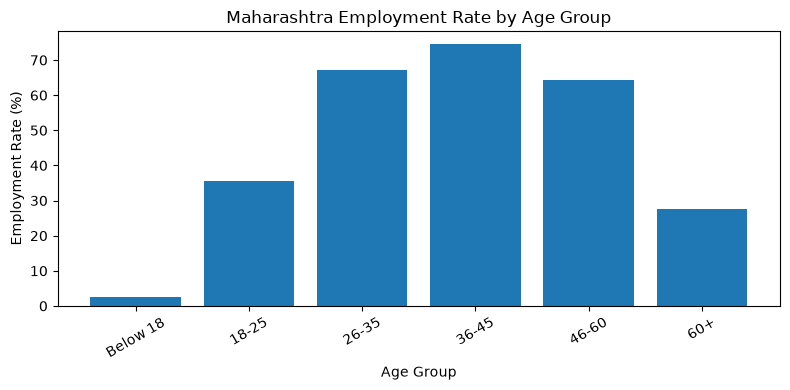

Frontend-ready data saved.


In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))

plt.bar(
    age_employment["age_group"].astype(str),
    age_employment["weighted_employment_rate_pct"]
)

plt.title("Maharashtra Employment Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Employment Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Save data for frontend use
age_employment.to_csv(
    "../outputs/plfs_employment_by_age.csv",
    index=False
)

print("Frontend-ready data saved.")

- Interpretation: The visualization clearly shows employment is highest for 36–45 and lowest for below 18 and 60+.

- Conclusion: This chart is suitable for the frontend employment dashboard. The CSV output is also saved for frontend use.

<h2>District Employment Visualization</h2>

- Create a district-level employment-rate dataset and visualization for the Maharashtra dashboard.

- Algorithm: Weighted aggregation + visualization.

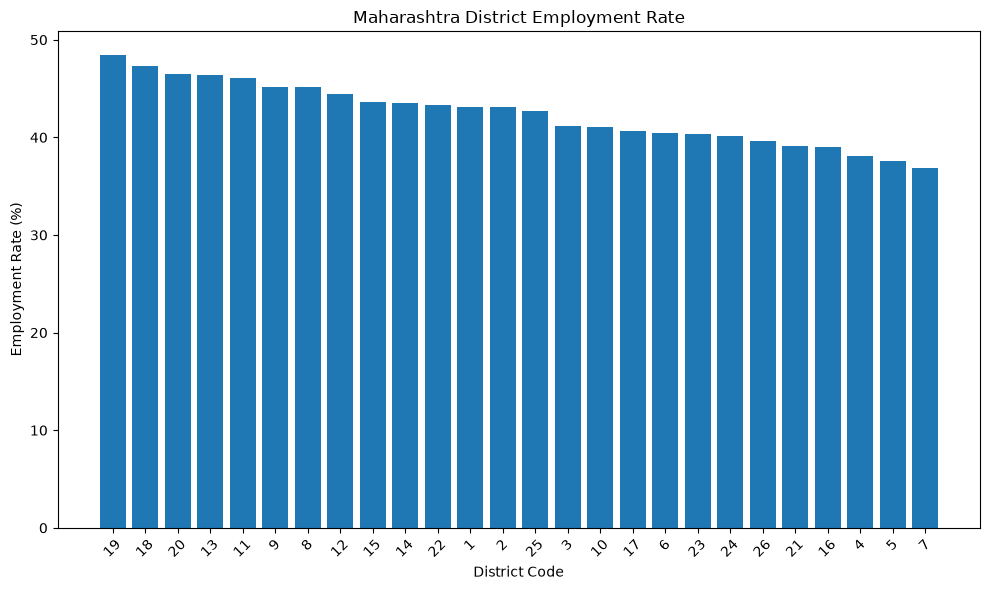

District employment data saved for frontend use.


In [26]:
import matplotlib.pyplot as plt

district_chart = district_employment.sort_values(
    "employment_rate_pct",
    ascending=False
).copy()

plt.figure(figsize=(10, 6))

plt.bar(
    district_chart["dc"].astype(str),
    district_chart["employment_rate_pct"]
)

plt.title("Maharashtra District Employment Rate")
plt.xlabel("District Code")
plt.ylabel("Employment Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Frontend-ready data
district_chart.to_csv(
    "../outputs/plfs_employment_by_district.csv",
    index=False
)

print("District employment data saved for frontend use.")

- Interpretation: District employment varies considerably, roughly 37%–48%, giving a useful geographic comparison.

- Conclusion: This visualization is suitable for the Maharashtra employment-rate dashboard/map.

<h2>Employment by Gender</h2>

- Compare weighted employment rates between male and female workers in Maharashtra.

- Algorithm: Weighted aggregation + visualization.

In [27]:
gender_employment = (
    maharashtra_plfs
    .groupby("sex")
    .apply(
        lambda g: pd.Series({
            "sample_size": len(g),
            "weighted_employment_rate_pct": (
                (g["employed_cws"] * g["mult"]).sum()
                / g["mult"].sum()
                * 100
            )
        }),
        include_groups=False
    )
    .reset_index()
)

gender_employment["weighted_employment_rate_pct"] = (
    gender_employment["weighted_employment_rate_pct"].round(2)
)

display(gender_employment)

,sex,sample_size,weighted_employment_rate_pct
0,1,19223.0,56.60
1,2,19527.0,29.19
2,3,1.0,0.00


- Interpretation: Employment differs substantially across the sex codes: 56.60%, 29.19%, and 0% for the very small third group.

- Conclusion: Gender/sex is useful for employment segmentation, but we should map the codes officially before displaying labels.

<h2>Earnings by Age Group</h2>

- Analyze how earnings vary across age groups to support salary and livelihood intelligence.
- Algorithm: Weighted aggregation.

In [28]:
# Keep only regular salaried/wage earnings
earnings_by_age = maharashtra_plfs[
    maharashtra_plfs["regular_earnings"] > 0
].copy()

earnings_by_age["age_group"] = pd.cut(
    earnings_by_age["age"],
    bins=[0, 18, 25, 35, 45, 60, 100],
    labels=[
        "Below 18",
        "18-25",
        "26-35",
        "36-45",
        "46-60",
        "60+"
    ]
)

age_earnings = (
    earnings_by_age
    .groupby("age_group", observed=False)
    .agg(
        sample_size=("regular_earnings", "size"),
        average_earnings=("regular_earnings", "mean")
    )
    .reset_index()
)

age_earnings["average_earnings"] = (
    age_earnings["average_earnings"].round(2)
)

display(age_earnings)

,age_group,sample_size,average_earnings
0,Below 18,79,10296.2
1,18-25,670,16808.2
2,26-35,1635,23730.93
3,36-45,1303,23397.65
4,46-60,1029,31693.56
5,60+,108,17131.81


- Interpretation: Average regular earnings are highest for the 46–60 group (₹31,693.56), with lower earnings among younger groups.

- Conclusion: Age can support salary/livelihood analysis, but sample sizes should be considered.

<h2>Employment by Vocational Training Duration</h2>

Check whether vocational-training duration is associated with employment outcomes.

Algorithm: Weighted group-wise employment-rate analysis.

In [29]:
voc_duration = (
    maharashtra_plfs[
        maharashtra_plfs["voc_dur"].notna()
    ]
    .groupby("voc_dur")
    .apply(
        lambda g: pd.Series({
            "sample_size": len(g),
            "weighted_employment_rate_pct": (
                (g["employed_cws"] * g["mult"]).sum()
                / g["mult"].sum()
                * 100
            )
        }),
        include_groups=False
    )
    .reset_index()
)

voc_duration["weighted_employment_rate_pct"] = (
    voc_duration["weighted_employment_rate_pct"].round(2)
)

display(
    voc_duration.sort_values(
        "weighted_employment_rate_pct",
        ascending=False
    )
)

,voc_dur,sample_size,weighted_employment_rate_pct
5,6.0,238.0,77.40
4,5.0,126.0,72.64
2,3.0,108.0,66.52
3,4.0,46.0,63.06
1,2.0,123.0,55.09
0,1.0,48.0,50.53


- Interpretation: Longer vocational-training durations show generally higher employment rates, with the highest observed rate at 77.40%.

- Conclusion: Training duration is promising for employment/training effectiveness analysis, but sample sizes are modest.

<h2>Employment by Vocational Training Type</h2>

Check whether different vocational-training types are associated with different employment rates.

Algorithm: Weighted group-wise employment-rate analysis.

In [30]:
voc_type_employment = (
    maharashtra_plfs[
        maharashtra_plfs["voc_typ"].notna()
    ]
    .groupby("voc_typ")
    .apply(
        lambda g: pd.Series({
            "sample_size": len(g),
            "weighted_employment_rate_pct": (
                (g["employed_cws"] * g["mult"]).sum()
                / g["mult"].sum()
                * 100
            )
        }),
        include_groups=False
    )
    .reset_index()
)

voc_type_employment["weighted_employment_rate_pct"] = (
    voc_type_employment["weighted_employment_rate_pct"].round(2)
)

display(
    voc_type_employment.sort_values(
        "weighted_employment_rate_pct",
        ascending=False
    )
)

,voc_typ,sample_size,weighted_employment_rate_pct
0,1.0,51.0,97.75
2,3.0,479.0,70.01
1,2.0,159.0,51.49


- Interpretation: Vocational-training type shows different employment rates (51.49%–97.75%), but the 97.75% group has only 51 records, so it needs caution.

- Conclusion: Training type can support training-effectiveness analysis, but we should prioritize categories with adequate sample sizes.

<h2>Vocational Training Completion & Certification</h2>

Check whether completing vocational training and having certification are associated with employment outcomes.

Algorithm: Weighted group-wise employment-rate analysis.

In [31]:
voc_completion = (
    maharashtra_plfs
    .groupby(["voc", "voc_cert"], dropna=False)
    .apply(
        lambda g: pd.Series({
            "sample_size": len(g),
            "weighted_employment_rate_pct": (
                (g["employed_cws"] * g["mult"]).sum()
                / g["mult"].sum()
                * 100
            )
        }),
        include_groups=False
    )
    .reset_index()
)

voc_completion["weighted_employment_rate_pct"] = (
    voc_completion["weighted_employment_rate_pct"].round(2)
)

display(voc_completion)

,voc,voc_cert,sample_size,weighted_employment_rate_pct
0,1.0,1.0,28.0,87.89
1,1.0,2.0,243.0,79.33
2,1.0,3.0,34.0,69.34
3,1.0,4.0,20.0,54.89
4,1.0,5.0,63.0,55.87
5,1.0,9.0,301.0,57.36
6,1.0,NaN,43.0,11.05
7,2.0,NaN,959.0,93.78
8,3.0,NaN,967.0,85.13
9,4.0,NaN,2998.0,92.06


- Interpretation: Certified vocational-training groups show higher employment rates than the uncertified/no-certification group, but several categories have small samples.

- Conclusion: Certification can support employment analysis, but we should use it carefully and map the codes officially.

<h2>Occupation Analysis with Reliable Samples</h2>

Identify major occupations among employed Maharashtra workers while excluding very small groups.

Algorithm: Weighted occupation distribution.

In [32]:
occupation_analysis = (
    maharashtra_plfs[
        (maharashtra_plfs["employed_cws"] == 1) &
        (maharashtra_plfs["ocu_cws"].notna())
    ]
    .groupby("ocu_cws")
    .agg(
        sample_size=("ocu_cws", "size"),
        weighted_workers=("mult", "sum")
    )
    .reset_index()
)

# Keep occupations with at least 100 surveyed records
occupation_analysis = occupation_analysis[
    occupation_analysis["sample_size"] >= 100
].copy()

occupation_analysis["share_pct"] = (
    occupation_analysis["weighted_workers"]
    / occupation_analysis["weighted_workers"].sum()
    * 100
).round(2)

occupation_analysis = occupation_analysis.sort_values(
    "weighted_workers",
    ascending=False
)

display(occupation_analysis.head(20))

,ocu_cws,sample_size,weighted_workers,share_pct
78,611.0,2686,330875228,20.48
115,921.0,2050,271683516,16.82
72,522.0,1467,153729059,9.52
116,931.0,1097,151569021,9.38
79,612.0,975,112848819,6.98
97,753.0,543,61189411,3.79
109,832.0,587,60792330,3.76
85,711.0,373,46399031,2.87
113,911.0,269,33667915,2.08
82,622.0,118,33247816,2.06


- Interpretation: A few occupations dominate the employed sample, with the largest occupation code representing 20.48% of weighted workers.

- Conclusion: Occupation is useful for career/labour-demand intelligence; next we'll analyze industry with reliable sample sizes.

<h2>Industry Analysis with Reliable Samples</h2>

Identify the major industries employing workers in Maharashtra while excluding very small industry groups.

Algorithm: Weighted industry distribution.

In [33]:
industry_analysis = (
    maharashtra_plfs[
        (maharashtra_plfs["employed_cws"] == 1) &
        (maharashtra_plfs["aind_cws"].notna())
    ]
    .groupby("aind_cws")
    .agg(
        sample_size=("aind_cws", "size"),
        weighted_workers=("mult", "sum")
    )
    .reset_index()
)

# Keep industries with at least 100 surveyed records
industry_analysis = industry_analysis[
    industry_analysis["sample_size"] >= 100
].copy()

industry_analysis["share_pct"] = (
    industry_analysis["weighted_workers"]
    / industry_analysis["weighted_workers"].sum()
    * 100
).round(2)

industry_analysis = industry_analysis.sort_values(
    "weighted_workers",
    ascending=False
)

display(industry_analysis.head(20))

,aind_cws,sample_size,weighted_workers,share_pct
0,1.0,5713,717620715,41.55
40,47.0,1585,175020249,10.13
35,41.0,1050,131064730,7.59
41,49.0,748,76143059,4.41
11,14.0,596,64286133,3.72
71,85.0,716,62458669,3.62
36,42.0,396,58882051,3.41
2,3.0,204,50669395,2.93
37,43.0,378,43814424,2.54
70,84.0,405,41649622,2.41


Interpretation: A few industries account for most weighted employment, with industry 1 contributing 41.55% in this filtered sample.

Conclusion: Industry is useful for labour-market intelligence and career recommendations; next we'll create a consolidated PLFS feature dataset.

<h2>Create Consolidated PLFS Feature Dataset</h2>

Save the cleaned Maharashtra PLFS features once so future notebooks/models can directly load them without repeating preprocessing.

Algorithm: Feature selection + persistent storage.

In [34]:
final_plfs_features = [
    "st",
    "dc",
    "age",
    "sex",
    "gedu_lvl",
    "tedu_lvl",
    "voc",
    "trg",
    "voc_fld",
    "voc_dur",
    "voc_typ",
    "voc_cert",
    "evr_wrk",
    "acws",
    "aind_cws",
    "ocu_cws",
    "ern_reg",
    "ern_self",
    "tothrs_wrk",
    "mult",
    "employed_cws"
]

plfs_feature_df = maharashtra_plfs[final_plfs_features].copy()

output_path = "../processed/maharashtra_plfs_features.csv"

plfs_feature_df.to_csv(
    output_path,
    index=False
)

print("Saved:", output_path)
print("Shape:", plfs_feature_df.shape)

Saved: ../processed/maharashtra_plfs_features.csv
Shape: (38751, 21)


Interpretation: The Maharashtra PLFS feature dataset is saved with 38,751 records and 21 features.

Conclusion: The cleaned PLFS data is now reusable without repeating this preprocessing.

<h2>Create Frontend-Ready PLFS Outputs</h2>

Save the key PLFS results as simple CSV files that your frontend can directly use for charts/maps.

Algorithm: Aggregation + export.

In [35]:
# 1. District employment
district_employment.to_csv(
    "../outputs/plfs_district_employment.csv",
    index=False
)

# 2. Age-group employment
age_employment.to_csv(
    "../outputs/plfs_age_employment.csv",
    index=False
)

# 3. Gender employment
gender_employment.to_csv(
    "../outputs/plfs_gender_employment.csv",
    index=False
)

# 4. Vocational training employment
voc_employment.to_csv(
    "../outputs/plfs_vocational_employment.csv",
    index=False
)

# 5. Occupation distribution
occupation_analysis.to_csv(
    "../outputs/plfs_occupation_distribution.csv",
    index=False
)

# 6. Industry distribution
industry_analysis.to_csv(
    "../outputs/plfs_industry_distribution.csv",
    index=False
)

# 7. Earnings by age
age_earnings.to_csv(
    "../outputs/plfs_earnings_by_age.csv",
    index=False
)

print("All frontend-ready PLFS outputs saved successfully.")

All frontend-ready PLFS outputs saved successfully.


Interpretation: All required PLFS summary files have been exported for reuse by the frontend.

Conclusion: Step 1 is complete. PLFS data is now cleaned, saved, and available for analysis/dashboard use without repeating the earlier processing.

<h2>Skill Demand Intelligence</h2>

Combine real PLFS labour-market context + NCS vacancy data + your training/skill data to build the Skill Demand Intelligence layer.

Algorithm: Demand aggregation/ranking first; ML only after establishing the demand signal.

<h3>Load NCS Vacancy Data</h3>
Load the NCS vacancy datasets and check their structure before connecting them to PLFS.